# HASTIKA @ ICON-2026 — Final Test Predictions
## Task A and Task B

### Input files
- `binary_train.csv` → Task A labelled training data
- `hastika_binary_test.csv` → Task A final test data
- `multiclass_train.csv` → Task B labelled training data
- `hastika_multiclass_test.csv` → Task B final test data

### Output
Two separate submissions:

```text
predictions_taskA.csv
predictions_taskA.zip
predictions_taskB.csv
predictions_taskB.zip
```

The competition format is `id,label`, with the IDs kept unchanged. Task A labels are `Hate` / `Non-Hate`; Task B labels are `Gender`, `Political`, `Religion`, `Geo-political`, `Violence`, `Others`.


## Reproducibility and analysis figures

Place this notebook beside the four required CSV files (`binary_train.csv`, `hastika_binary_test.csv`, `multiclass_train.csv`, and `hastika_multiclass_test.csv`). The optional validation-input CSVs are included in the submission folder for completeness but are not used for fitting or threshold selection. Running all cells regenerates prediction CSV/ZIP files and diagnostic figures in `figures/`. The blind test files have no gold labels, so test-set accuracy/F1 is not calculated here.


In [16]:
import pandas as pd
import numpy as np
import re
import html
import unicodedata
import zipfile

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score

## 1. Load all four files

In [2]:
TRAIN_A = "binary_train.csv"
TEST_A = "hastika_binary_test.csv"

TRAIN_B = "multiclass_train.csv"
TEST_B = "hastika_multiclass_test.csv"

train_a = pd.read_csv(TRAIN_A)
test_a = pd.read_csv(TEST_A)

train_b = pd.read_csv(TRAIN_B)
test_b = pd.read_csv(TEST_B)

print("Task A train:", train_a.shape)
print("Task A test :", test_a.shape)
print("Task B train:", train_b.shape)
print("Task B test :", test_b.shape)

print("\nTask A test columns:", test_a.columns.tolist())
print("Task B test columns:", test_b.columns.tolist())

print("\nTask A test sample:")
display(test_a.head())

print("\nTask B test sample:")
display(test_b.head())


Task A train: (6446, 3)
Task A test : (806, 2)
Task B train: (3159, 3)
Task B test : (396, 2)

Task A test columns: ['id', 'Comment']
Task B test columns: ['id', 'Comment']

Task A test sample:


,id,Comment
0,5820,ella muslims kettoralla
1,5800,@Manu sare aythu nin en madteya
2,2707,Olle hudgun kalkondalle ð¤¨ð¤¨ð¤¨
3,1518,Uttara Karnataka martiro e sarkarakke ugiri
4,6829,Doverani bevarsi ivalu



Task B test sample:


,id,Comment
0,6820,"Inta ketta Sonu anta KRIMI ellu nodilla, avara..."
1,6507,Vayassige Adru maryade kodbekittu nimmind jana...
2,1697,Namma india ???? dalli yalla jaati yu irabeko ...
3,6214,Huchhanan Maga pratam
4,3145,Bidi hogli anbedi ma nim maglu matte haage antira


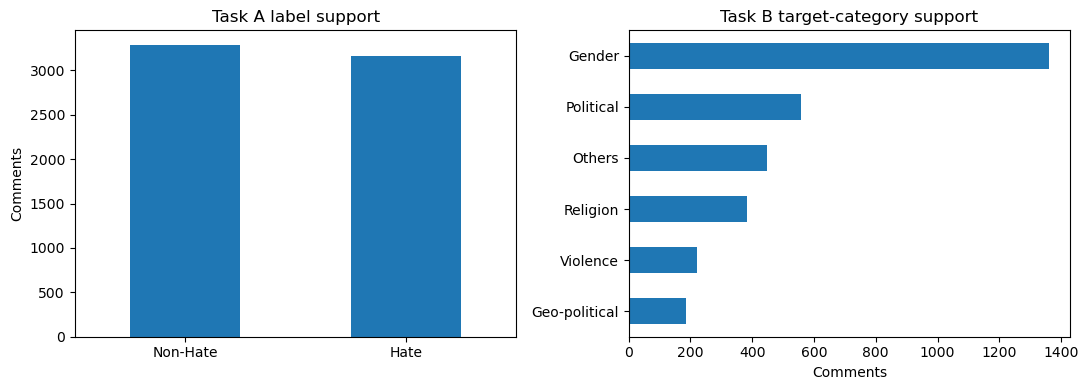

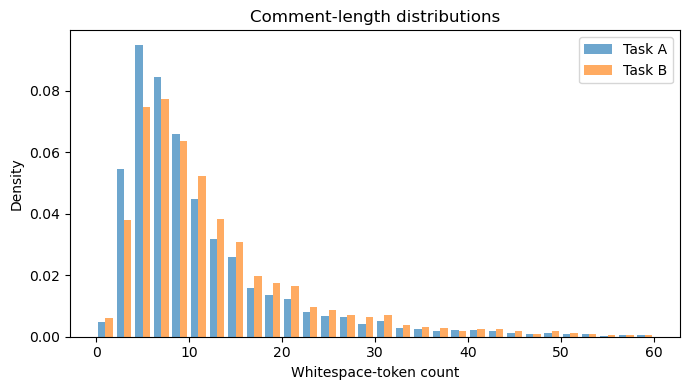

Task A rows: 6446 | Task B rows: 3159
Task A median token count: 8.0
Task B median token count: 9.0
Task B class proportions:


,percent
Hate Category,
Gender,43.11
Political,17.70
Others,14.21
Religion,12.09
Violence,7.00
Geo-political,5.89


In [3]:
# ============================================================
# DATASET OVERVIEW — LABEL SUPPORT AND COMMENT LENGTH
# ============================================================
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, classification_report

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_a["Label"].value_counts().reindex(["Non-Hate", "Hate"]).plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Task A label support")
axes[0].set_ylabel("Comments")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

train_b["Hate Category"].value_counts().sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Task B target-category support")
axes[1].set_xlabel("Comments")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "dataset_label_support.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
length_a = train_a["Comment"].fillna("").astype(str).str.split().str.len()
length_b = train_b["Comment"].fillna("").astype(str).str.split().str.len()
ax.hist([length_a, length_b], bins=range(0, 62, 2), density=True,
        alpha=0.65, label=["Task A", "Task B"])
ax.set_xlabel("Whitespace-token count")
ax.set_ylabel("Density")
ax.set_title("Comment-length distributions")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "comment_length_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

print("Task A rows:", len(train_a), "| Task B rows:", len(train_b))
print("Task A median token count:", float(length_a.median()))
print("Task B median token count:", float(length_b.median()))
print("Task B class proportions:")
display((train_b["Hate Category"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())


# TASK A — FINAL PREDICTIONS

For Task A we use the final classical approach developed during the competition:

- 5-fold stratified out-of-fold (OOF) training
- cleaned `char_wb` TF-IDF
- raw `char_wb` TF-IDF
- word TF-IDF
- Linear SVM classifiers
- OOF ensemble-weight selection
- OOF threshold selection for Macro-F1
- five-fold score averaging for the final blind test

The official test labels are hidden, so no information from the test file is used to tune the model.


In [4]:
# ============================================================
# TASK A — PREPARE TEXT
# ============================================================

X_raw = train_a["Comment"].fillna("").astype(str).to_numpy()
y_a = train_a["Label"].to_numpy()

T_raw = test_a["Comment"].fillna("").astype(str).to_numpy()


def clean_text(s):
    s = html.unescape(str(s))
    s = re.sub(r"<br\s*/?>", " ", s, flags=re.I)
    s = re.sub(r"<[^>]+>", " ", s)
    s = unicodedata.normalize("NFKC", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s


X_clean = np.array(
    [clean_text(s) for s in X_raw],
    dtype=object
)

T_clean = np.array(
    [clean_text(s) for s in T_raw],
    dtype=object
)

print("Training comments:", len(X_raw))
print("Final test comments:", len(T_raw))


Training comments: 6446
Final test comments: 806


In [5]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_clean = np.empty(len(y_a), dtype=float)
oof_raw = np.empty(len(y_a), dtype=float)
oof_word = np.empty(len(y_a), dtype=float)

fold_test_clean = []
fold_test_raw = []
fold_test_word = []


def oriented_score(model, X_features):
    score = model.decision_function(X_features)

    # Make larger scores consistently mean "Non-Hate".
    if model.classes_[1] != "Non-Hate":
        score = -score

    return score


for fold, (tr, va) in enumerate(
    skf.split(X_raw, y_a),
    start=1
):
    print(f"Task A — fold {fold}/5")

    # --------------------------------------------------------
    # Model 1: cleaned char_wb, 2-6
    # --------------------------------------------------------
    vec_clean = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 6),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    Xtr = vec_clean.fit_transform(X_clean[tr])
    Xva = vec_clean.transform(X_clean[va])

    model_clean = LinearSVC(
        C=0.5,
        max_iter=5000,
        random_state=42
    )

    model_clean.fit(Xtr, y_a[tr])

    oof_clean[va] = oriented_score(
        model_clean,
        Xva
    )

    fold_test_clean.append(
        oriented_score(
            model_clean,
            vec_clean.transform(T_clean)
        )
    )

    # --------------------------------------------------------
    # Model 2: raw char_wb, 2-5
    # --------------------------------------------------------
    vec_raw = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        min_df=2,
        max_features=40000,
        sublinear_tf=True
    )

    Xtr = vec_raw.fit_transform(X_raw[tr])
    Xva = vec_raw.transform(X_raw[va])

    model_raw = LinearSVC(
        C=0.5,
        max_iter=5000,
        random_state=42
    )

    model_raw.fit(Xtr, y_a[tr])

    oof_raw[va] = oriented_score(
        model_raw,
        Xva
    )

    fold_test_raw.append(
        oriented_score(
            model_raw,
            vec_raw.transform(T_raw)
        )
    )

    # --------------------------------------------------------
    # Model 3: word TF-IDF, 1-2
    # --------------------------------------------------------
    vec_word = TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=1,
        max_features=30000,
        sublinear_tf=True
    )

    Xtr = vec_word.fit_transform(X_raw[tr])
    Xva = vec_word.transform(X_raw[va])

    model_word = LinearSVC(
        C=0.5,
        max_iter=5000,
        random_state=42
    )

    model_word.fit(Xtr, y_a[tr])

    oof_word[va] = oriented_score(
        model_word,
        Xva
    )

    fold_test_word.append(
        oriented_score(
            model_word,
            vec_word.transform(T_raw)
        )
    )

print("OOF training complete.")


Task A — fold 1/5
Task A — fold 2/5
Task A — fold 3/5
Task A — fold 4/5
Task A — fold 5/5
OOF training complete.


In [6]:
oof_stats = {}
oof_norm = {}

for name, score in [
    ("clean", oof_clean),
    ("raw", oof_raw),
    ("word", oof_word)
]:
    mean_score = score.mean()
    std_score = score.std()

    oof_stats[name] = (
        mean_score,
        std_score
    )

    oof_norm[name] = (
        score - mean_score
    ) / std_score


In [7]:
# ============================================================
# TASK A — FIND BEST ENSEMBLE WEIGHTS + THRESHOLD
# ============================================================

def best_threshold(scores, labels):
    positive = (
        labels == "Non-Hate"
    ).astype(int)

    order = np.argsort(
        -scores,
        kind="mergesort"
    )

    sorted_scores = scores[order]
    sorted_y = positive[order]

    tp = np.cumsum(sorted_y)
    fp = np.cumsum(1 - sorted_y)

    total_pos = tp[-1]
    total_neg = fp[-1]

    fn = total_pos - tp
    tn = total_neg - fp

    f1_pos = np.divide(
        2 * tp,
        2 * tp + fp + fn,
        out=np.zeros_like(
            tp,
            dtype=float
        ),
        where=(2 * tp + fp + fn) != 0
    )

    f1_neg = np.divide(
        2 * tn,
        2 * tn + fn + fp,
        out=np.zeros_like(
            tn,
            dtype=float
        ),
        where=(2 * tn + fn + fp) != 0
    )

    macro_f1 = (
        f1_pos + f1_neg
    ) / 2

    best_index = int(
        np.argmax(macro_f1)
    )

    threshold = float(
        sorted_scores[best_index]
    )

    pred = np.where(
        scores >= threshold,
        "Non-Hate",
        "Hate"
    )

    return (
        float(macro_f1[best_index]),
        float(
            accuracy_score(
                labels,
                pred
            )
        ),
        threshold
    )


best_a = None

for clean_weight in np.arange(
    0.0, 1.001, 0.05
):
    for raw_weight in np.arange(
        0.0,
        1.001 - clean_weight,
        0.05
    ):
        word_weight = (
            1
            - clean_weight
            - raw_weight
        )

        combined = (
            clean_weight * oof_norm["clean"]
            + raw_weight * oof_norm["raw"]
            + word_weight * oof_norm["word"]
        )

        f1, acc, threshold = best_threshold(
            combined,
            y_a
        )

        if (
            best_a is None
            or f1 > best_a["macro_f1"]
        ):
            best_a = {
                "clean_weight": float(clean_weight),
                "raw_weight": float(raw_weight),
                "word_weight": float(word_weight),
                "threshold": float(threshold),
                "macro_f1": float(f1),
                "accuracy": float(acc)
            }

print("Best Task A OOF configuration:")
print(best_a)


Best Task A OOF configuration:
{'clean_weight': 0.55, 'raw_weight': 0.45, 'word_weight': -5.551115123125783e-17, 'threshold': -0.006983970577815651, 'macro_f1': 0.8170923282410423, 'accuracy': 0.8174061433447098}


In [8]:
# ============================================================
# TASK A — PREDICT THE NEW FINAL TEST SET
# ============================================================

test_clean = np.mean(
    fold_test_clean,
    axis=0
)

test_raw = np.mean(
    fold_test_raw,
    axis=0
)

test_word = np.mean(
    fold_test_word,
    axis=0
)

test_clean_norm = (
    test_clean - oof_stats["clean"][0]
) / oof_stats["clean"][1]

test_raw_norm = (
    test_raw - oof_stats["raw"][0]
) / oof_stats["raw"][1]

test_word_norm = (
    test_word - oof_stats["word"][0]
) / oof_stats["word"][1]

final_a_score = (
    best_a["clean_weight"] * test_clean_norm
    + best_a["raw_weight"] * test_raw_norm
    + best_a["word_weight"] * test_word_norm
)

final_a_pred = np.where(
    final_a_score >= best_a["threshold"],
    "Non-Hate",
    "Hate"
)

predictions_taskA = pd.DataFrame({
    "id": test_a["id"],
    "label": final_a_pred
})

print("Task A predictions:", len(predictions_taskA))
print(predictions_taskA["label"].value_counts())


Task A predictions: 806
label
Non-Hate    417
Hate        389
Name: count, dtype: int64


In [20]:
assert len(predictions_taskA) == len(test_a)
assert predictions_taskA.columns.tolist() == [
    "id",
    "label"
]
assert predictions_taskA["id"].equals(
    test_a["id"]
)
assert predictions_taskA["id"].is_unique
assert predictions_taskA["label"].notna().all()
assert set(
    predictions_taskA["label"]
).issubset({
    "Hate",
    "Non-Hate"
})

predictions_taskA.to_csv(
    "predictions_taskA.csv",
    index=False,
    encoding="utf-8"
)

with zipfile.ZipFile(
    "predictions_taskA.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:
    zipf.write(
        "predictions_taskA.csv",
        arcname="predictions.csv"
    )

print("Task A CSV created: predictions_taskA.csv")
print("Task A ZIP created: predictions_taskA.zip")

print("========================================")
print("TASK A - LOCAL OOF PERFORMANCE")
print("========================================")

print("Accuracy :", round(best_a["accuracy"], 4))
print("Macro-F1 :", round(best_a["macro_f1"], 4))

print("\nSelected Ensemble:")
print("Clean char_wb weight :", best_a["clean_weight"])
print("Raw char_wb weight   :", best_a["raw_weight"])
print("Word TF-IDF weight   :", best_a["word_weight"])

Task A CSV created: predictions_taskA.csv
Task A ZIP created: predictions_taskA.zip
TASK A - LOCAL OOF PERFORMANCE
Accuracy : 0.8174
Macro-F1 : 0.8171

Selected Ensemble:
Clean char_wb weight : 0.55
Raw char_wb weight   : 0.45
Word TF-IDF weight   : -5.551115123125783e-17


# TASK B — FINAL PREDICTIONS

Your final Task B notebook selected:

```text
analyzer        = char_wb
ngram_range    = (2,5)
min_df         = 2
max_features   = 30000
class_weight   = balanced
C              = 0.4
```

with the best local holdout Macro-F1 from the tested settings.

We now train that model on **all 3,159 labelled Task B examples** and predict the new blind test file.


In [10]:
X_B = train_b["Comment"].fillna("").astype(str)
y_B = train_b["Hate Category"]

X_B_test = test_b["Comment"].fillna("").astype(str)

taskB_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(2, 5),
    min_df=2,
    max_features=30000
)

X_B_full = taskB_vectorizer.fit_transform(
    X_B
)

X_B_final_test = taskB_vectorizer.transform(
    X_B_test
)

print("Task B training features:", X_B_full.shape)
print("Task B final-test features:", X_B_final_test.shape)

taskB_model = LinearSVC(
    C=0.4,
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

taskB_model.fit(
    X_B_full,
    y_B
)

final_b_pred = taskB_model.predict(
    X_B_final_test
)

print("Task B predictions:", len(final_b_pred))
print(
    pd.Series(final_b_pred).value_counts()
)


Task B training features: (3159, 30000)
Task B final-test features: (396, 30000)
Task B predictions: 396
Gender           191
Political         64
Others            46
Religion          41
Geo-political     31
Violence          23
Name: count, dtype: int64


In [18]:
valid_taskB_labels = {
    "Gender", "Political", "Religion",
    "Geo-political", "Violence", "Others"
}
predictions_taskB = pd.DataFrame({
    "id": test_b["id"],
    "label": final_b_pred
})

assert len(predictions_taskB) == len(test_b)
assert predictions_taskB.columns.tolist() == ["id", "label"]
assert predictions_taskB["id"].equals(test_b["id"])
assert predictions_taskB["id"].is_unique
assert predictions_taskB["label"].notna().all()
assert set(predictions_taskB["label"]).issubset(valid_taskB_labels)

predictions_taskB.to_csv("predictions_taskB.csv", index=False, encoding="utf-8")
with zipfile.ZipFile("predictions_taskB.zip", "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write("predictions_taskB.csv", arcname="predictions.csv")

print("Task B CSV created: predictions_taskB.csv")
print("Task B ZIP created: predictions_taskB.zip")
print("Evaluation diagnostics are generated in the final analysis cells.")


Task B CSV created: predictions_taskB.csv
Task B ZIP created: predictions_taskB.zip
Evaluation diagnostics are generated in the final analysis cells.


# FINAL CHECK

You should now have four files:

```text
predictions_taskA.csv
predictions_taskA.zip

predictions_taskB.csv
predictions_taskB.zip
```

For CodaBench, upload the **ZIP**, not the CSV directly.

Each ZIP contains a flat `predictions.csv`.


In [12]:
print("TASK A")
print(pd.read_csv("predictions_taskA.csv").head())
print(pd.read_csv("predictions_taskA.csv").shape)
print()

print("TASK B")
print(pd.read_csv("predictions_taskB.csv").head())
print(pd.read_csv("predictions_taskB.csv").shape)
print()

with zipfile.ZipFile(
    "predictions_taskA.zip",
    "r"
) as z:
    print("Task A ZIP:", z.namelist())

with zipfile.ZipFile(
    "predictions_taskB.zip",
    "r"
) as z:
    print("Task B ZIP:", z.namelist())


TASK A
     id     label
0  5820      Hate
1  5800  Non-Hate
2  2707  Non-Hate
3  1518      Hate
4  6829      Hate
(806, 2)

TASK B
     id     label
0  6820    Others
1  6507    Gender
2  1697  Religion
3  6214    Gender
4  3145    Gender
(396, 2)

Task A ZIP: ['predictions.csv']
Task B ZIP: ['predictions.csv']


## Diagnostic evaluation plots

The next cells plot only labelled-data cross-validation predictions. They do **not** score the hidden test files. The Task A confusion matrix is derived from the OOF scores already produced above. Task B uses fresh stratified folds to retain one held-out prediction per training row, then reports fold-independent aggregate diagnostics.

Task A OOF accuracy: 0.8174
Task A OOF Macro-F1: 0.8171


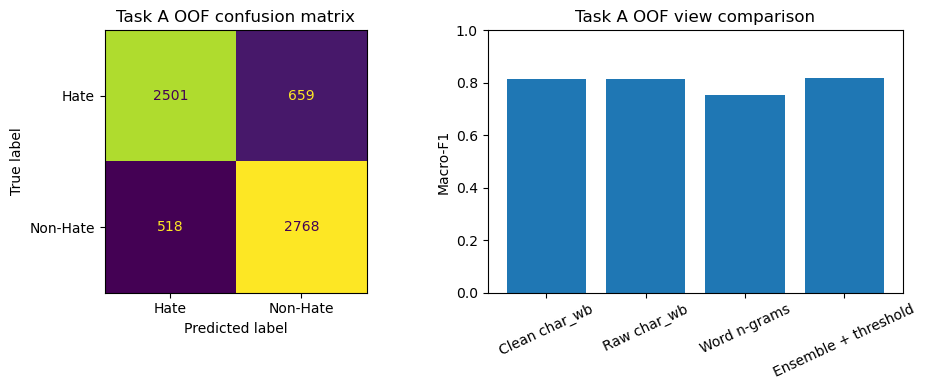

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, accuracy_score

taskA_oof_pred = np.where(
    (best_a["clean_weight"] * oof_norm["clean"]
     + best_a["raw_weight"] * oof_norm["raw"]
     + best_a["word_weight"] * oof_norm["word"]) >= best_a["threshold"],
    "Non-Hate", "Hate"
)
print("Task A OOF accuracy:", round(accuracy_score(y_a, taskA_oof_pred), 4))
print("Task A OOF Macro-F1:", round(f1_score(y_a, taskA_oof_pred, average="macro"), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_a, taskA_oof_pred, labels=["Hate", "Non-Hate"],
    display_labels=["Hate", "Non-Hate"], ax=axes[0], colorbar=False
)
axes[0].set_title("Task A OOF confusion matrix")
view_scores = {
    "Clean char_wb": f1_score(y_a, np.where(oof_norm["clean"] >= 0, "Non-Hate", "Hate"),
                              average="macro"),
    "Raw char_wb": f1_score(y_a, np.where(oof_norm["raw"] >= 0, "Non-Hate", "Hate"),
                            average="macro"),
    "Word n-grams": f1_score(y_a, np.where(oof_norm["word"] >= 0, "Non-Hate", "Hate"),
                             average="macro"),
    "Ensemble + threshold": f1_score(y_a, taskA_oof_pred, average="macro")
}
axes[1].bar(list(view_scores.keys()), list(view_scores.values()))
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Task A OOF view comparison")
axes[1].tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIG_DIR / "taskA_oof_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()


Task B diagnostic fold 1/5
Task B diagnostic fold 2/5
Task B diagnostic fold 3/5
Task B diagnostic fold 4/5
Task B diagnostic fold 5/5
Task B OOF accuracy: 0.698
Task B OOF Macro-F1: 0.6174


,precision,recall,f1-score,support
Gender,0.761,0.826,0.792,1362.000
Political,0.769,0.767,0.768,559.000
Religion,0.723,0.743,0.733,382.000
Geo-political,0.572,0.575,0.574,186.000
Violence,0.463,0.339,0.392,221.000
Others,0.486,0.412,0.446,449.000
accuracy,0.698,0.698,0.698,0.698
macro avg,0.629,0.611,0.617,3159.000
weighted avg,0.687,0.698,0.691,3159.000


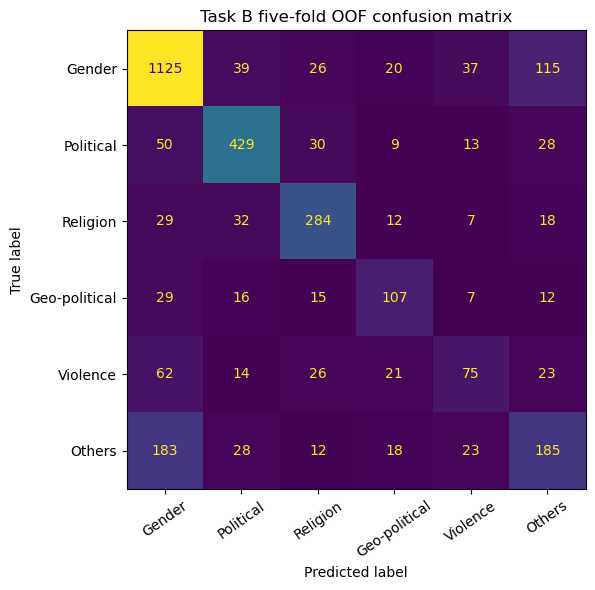

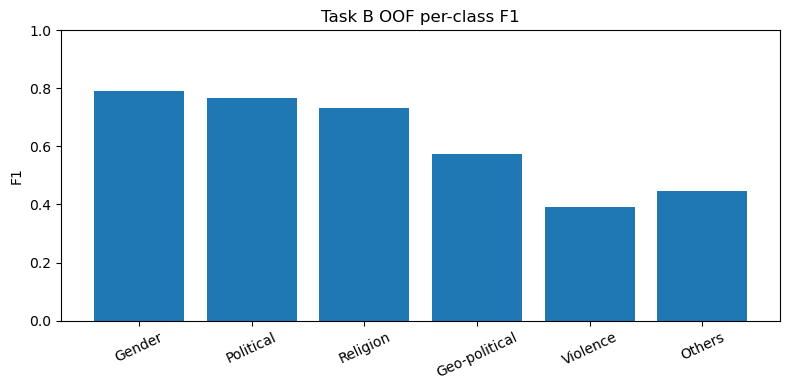

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_B_text = train_b["Comment"].fillna("").astype(str).to_numpy()
y_B_text = train_b["Hate Category"].astype(str).to_numpy()
taskB_oof_pred = np.empty(len(y_B_text), dtype=object)

for fold, (tr_idx, va_idx) in enumerate(cv.split(X_B_text, y_B_text), start=1):
    print(f"Task B diagnostic fold {fold}/5")
    vec = TfidfVectorizer(
        analyzer="char_wb", ngram_range=(2, 5),
        min_df=2, max_features=30000
    )
    Xtr = vec.fit_transform(X_B_text[tr_idx])
    Xva = vec.transform(X_B_text[va_idx])
    clf = LinearSVC(C=0.4, class_weight="balanced", random_state=42, max_iter=5000)
    clf.fit(Xtr, y_B_text[tr_idx])
    taskB_oof_pred[va_idx] = clf.predict(Xva)

labels_b = ["Gender", "Political", "Religion", "Geo-political", "Violence", "Others"]
print("Task B OOF accuracy:", round(accuracy_score(y_B_text, taskB_oof_pred), 4))
print("Task B OOF Macro-F1:", round(f1_score(y_B_text, taskB_oof_pred, average="macro"), 4))
display(pd.DataFrame(classification_report(
    y_B_text, taskB_oof_pred, labels=labels_b, output_dict=True, zero_division=0
)).T.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_B_text, taskB_oof_pred, labels=labels_b,
    display_labels=labels_b, xticks_rotation=35,
    ax=ax, colorbar=False
)
ax.set_title("Task B five-fold OOF confusion matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "taskB_oof_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

per_class = f1_score(y_B_text, taskB_oof_pred, labels=labels_b,
                     average=None, zero_division=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels_b, per_class)
ax.set_ylim(0, 1)
ax.set_ylabel("F1")
ax.set_title("Task B OOF per-class F1")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIG_DIR / "taskB_oof_per_class_f1.png", dpi=180, bbox_inches="tight")
plt.show()


,C,mean_macro_f1,std_macro_f1
0,0.1,0.5872,0.0172
1,0.4,0.6048,0.0192
2,1.0,0.5857,0.0217


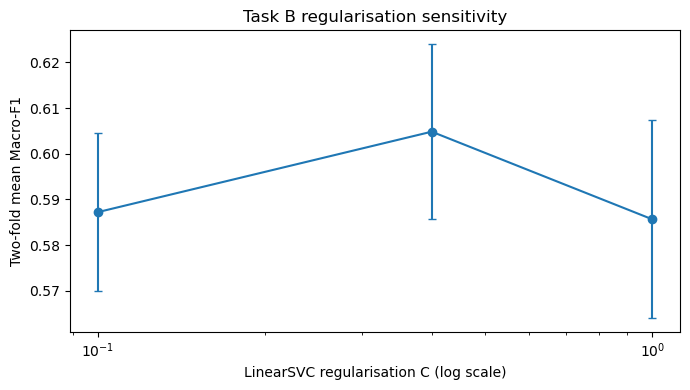

In [15]:
C_values = [0.1, 0.4, 1.0]
sweep_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
sweep_results = []

for C_value in C_values:
    fold_scores = []
    for tr_idx, va_idx in sweep_cv.split(X_B_text, y_B_text):
        vec = TfidfVectorizer(
            analyzer="char_wb", ngram_range=(2, 5),
            min_df=2, max_features=30000
        )
        Xtr = vec.fit_transform(X_B_text[tr_idx])
        Xva = vec.transform(X_B_text[va_idx])
        clf = LinearSVC(C=C_value, class_weight="balanced",
                        random_state=42, max_iter=5000)
        clf.fit(Xtr, y_B_text[tr_idx])
        pred = clf.predict(Xva)
        fold_scores.append(f1_score(y_B_text[va_idx], pred,
                                    average="macro", zero_division=0))
    sweep_results.append({"C": C_value,
                          "mean_macro_f1": float(np.mean(fold_scores)),
                          "std_macro_f1": float(np.std(fold_scores))})

sweep_df = pd.DataFrame(sweep_results)
display(sweep_df.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(sweep_df["C"], sweep_df["mean_macro_f1"],
            yerr=sweep_df["std_macro_f1"], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("LinearSVC regularisation C (log scale)")
ax.set_ylabel("Two-fold mean Macro-F1")
ax.set_title("Task B regularisation sensitivity")
fig.tight_layout()
fig.savefig(FIG_DIR / "taskB_C_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()


## Reproducibility notes

- Random seed: `42`.
- Task A threshold/blend search uses only out-of-fold training scores.
- Task B diagnostic folds are stratified and fit their vectorisers inside each training fold.
- The final blind-test CSVs contain `id,label`, preserve test-file ID order, and are also zipped with the required inner filename `predictions.csv`.
- Do not interpret blind-test predictions as evaluation results: the supplied test CSVs contain no gold labels.
